In [1]:
import toytree
import toyplot
import numpy as np
import pandas as pd
import toyplot.svg

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Make a ultrametric tree

In [3]:
# read tree
tre = toytree.io.tree("./sptree-accpplabel-filtered-rooted-singlecopy.nwk")

In [6]:
clock_fit = toytree.mod.edges_make_ultrametric_pl_clock(tre, full=True, inplace=True)

2026-07-21 13:14:58.288 | DEBUG    | toytree.mod._src.penalized_likelihood.pl_clock:edges_make_ultrametric_pl_clock:270 - clock multistart best objective=5.484620848880384, start=0, nstarts=1


In [7]:
# get ultrametric tree
tree=clock_fit["tree"]

# 2. Read the trait table and create a fitted MK model

In [8]:
# ladderize the tree
tree = toytree.mod.ladderize(tree, direction=False)

In [11]:
# read trait table
df = pd.read_csv("./traits_for_reconstruction.tsv", sep='\t')

In [12]:
# convert color from string (white, pink, yellow) to 0,1,2
cmap = {'white': 0, 'pink': 1, 'yellow': 2}
df['color_num'] = df['color'].map(cmap)

In [13]:
# add color, beak and tube information to the tree
# create dictionary
color_map = dict(zip(df['species'], df['color_num'].astype(object)))
beak_map = dict(zip(df['species'], df['beak'].astype(object)))
tube_map = dict(zip(df['species'], df['tube'].astype(object)))

# add these traits as node feature
tree = tree.set_node_data(feature="color", data=color_map)
tree = tree.set_node_data(feature="beak", data=beak_map)
tree = tree.set_node_data(feature="tube", data=tube_map)

In [14]:
# fit ARD model
color_fit = tree.pcm.fit_discrete_ctmc(data="color", nstates=3, model="ARD")
beak_fit = tree.pcm.fit_discrete_ctmc(data="beak", nstates=2, model="ARD")
tube_fit = tree.pcm.fit_discrete_ctmc(data="tube", nstates=2, model="ARD")
#other models
fit_er = tree.pcm.fit_discrete_ctmc(data="color", nstates=3, model="ER")
fit_sym = tree.pcm.fit_discrete_ctmc(data="color", nstates=3, model="SYM")

In [15]:
# 'white': 0, 'pink': 1, 'yellow': 2
color_fit.qmatrix

array([[-1.28724654e+03,  1.28669513e+03,  5.51407986e-01],
       [ 1.22115630e+02, -1.27526769e+02,  5.41113868e+00],
       [ 1.35536913e+01,  4.90388199e-05, -1.35537403e+01]])

In [16]:
# galea:0, beak:1
beak_fit.qmatrix

array([[-0.66769681,  0.66769681],
       [ 1.97026838, -1.97026838]])

In [17]:
# short:0, long:1
tube_fit.qmatrix

array([[-1.30499969,  1.30499969],
       [ 7.1202445 , -7.1202445 ]])

# 3. Simulate stochastic mapping

In [18]:
# simulate stochastic mapping
color_result = tree.pcm.simulate_stochastic_map(
data="color",
model_fit=color_fit,
nreplicates=100,
seed=3,
return_summary=True
)

In [19]:
# simulate stochastic mapping
beak_result = tree.pcm.simulate_stochastic_map(
data="beak",
model_fit=beak_fit,
nreplicates=100,
seed=3,
return_summary=True
)

In [20]:
# simulate stochastic mapping
tube_result = tree.pcm.simulate_stochastic_map(
data="tube",
model_fit=tube_fit,
nreplicates=100,
seed=3,
return_summary=True
)

# 4. check the results

In [21]:
# check the result
columns = ["map_id", "edge_id", "child", "parent", "state", "t_start", "t_end", "duration"]
color_result["segments"][columns].head(12)

,map_id,edge_id,child,parent,state,t_start,t_end,duration
0,0,0,0,164,1,0.000000,0.004708,0.004708
1,0,0,0,164,0,0.004708,0.005359,0.000651
2,0,0,0,164,1,0.005359,0.016197,0.010838
3,0,0,0,164,0,0.016197,0.016659,0.000462
4,0,0,0,164,1,0.016659,0.034848,0.018189
5,0,0,0,164,0,0.034848,0.035539,0.000691
6,0,0,0,164,1,0.035539,0.043683,0.008144
7,0,0,0,164,2,0.043683,0.049395,0.005712
8,0,0,0,164,0,0.049395,0.050398,0.001003
9,0,0,0,164,1,0.050398,0.058867,0.008469


In [22]:
# The dwell table reports total branch time spent in each state for each map replicate.
# color_result["dwell"].head(9)

In [23]:
# further examining statistics across replicates.
replicate_dwell = (
    color_result["dwell"].pivot(index="map_id", columns="state", values="total_time")
    .round(3)
)
replicate_dwell.head(9)

state,0,1,2
map_id,,,
0,0.626,6.429,2.753
1,0.688,7.112,2.008
2,0.599,5.692,3.517
3,0.591,5.920,3.298
4,0.662,6.623,2.523
5,0.601,6.042,3.165
6,0.680,6.365,2.764
7,0.655,6.303,2.851
8,0.708,6.623,2.477


In [24]:
# transition rate (0-white, 1-pink, 2-yellow)
color_transition = color_result["transitions"]

# create transition column
state_names = {0: "White", 1: "Pink", 2: "Yellow"}
color_transition['from_label'] = color_transition['from_state_idx'].map(state_names)
color_transition['to_label'] = color_transition['to_state_idx'].map(state_names)

color_transition['transition'] = color_transition['from_label'] + " → " + color_transition['to_label']

color_transition.head(9)

,map_id,from_state_idx,to_state_idx,from_state,to_state,count,from_label,to_label,transition
0,0,0,1,0,1,834,White,Pink,White → Pink
1,0,1,0,1,0,797,Pink,White,Pink → White
2,0,1,2,1,2,41,Pink,Yellow,Pink → Yellow
3,0,2,0,2,0,37,Yellow,White,Yellow → White
4,1,0,1,0,1,940,White,Pink,White → Pink
5,1,1,0,1,0,896,Pink,White,Pink → White
6,1,1,2,1,2,41,Pink,Yellow,Pink → Yellow
7,1,2,0,2,0,44,Yellow,White,Yellow → White
8,2,0,1,0,1,765,White,Pink,White → Pink


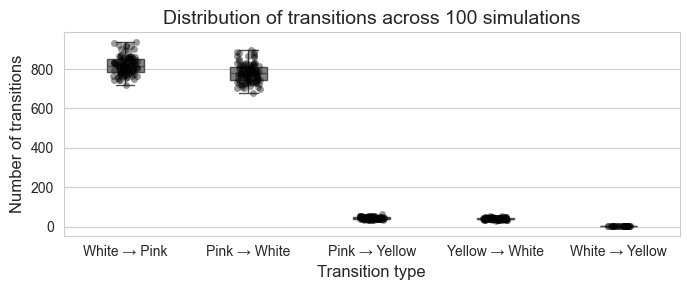

In [25]:
# set up
plt.figure(figsize=(7, 3))
sns.set_style("whitegrid")

# draw the xoxplot
sns.boxplot(
    data=color_transition, 
    x='transition', 
    y='count', 
    color = "grey",
    showfliers=False,      # Hide outliers to avoid double-plotting dots 
    width=0.3
)

# overlay the dots
sns.stripplot(
    data=color_transition, 
    x='transition', 
    y='count', 
    color='black', 
    size=5, 
    alpha=0.4,            
    jitter=True            # Spreads dots horizontally so they don't stack
)

# add labels
plt.title("Distribution of transitions across 100 simulations", fontsize=14)
plt.xlabel("Transition type", fontsize=12)
plt.ylabel("Number of transitions", fontsize=12)
# plt.xticks(rotation=45)

plt.tight_layout()
# plt.savefig("transition_plot.png")

In [26]:
# further examining statistics across replicates.
replicate_dwell = (
    beak_result["dwell"].pivot(index="map_id", columns="state", values="total_time")
    .round(3)
)
replicate_dwell.head(9)

state,0,1
map_id,,
0,4.196,5.613
1,4.801,5.008
2,4.752,5.057
3,4.539,5.270
4,4.777,5.031
5,4.038,5.770
6,4.714,5.094
7,3.828,5.980
8,4.347,5.461


In [27]:
# transition rate (0-short, 1-long)
beak_transition = beak_result["transitions"]

# create transition column
state_names = {0: "Short beak (galea)", 1: "Long beak"}
beak_transition['from_label'] = beak_transition['from_state_idx'].map(state_names)
beak_transition['to_label'] = beak_transition['to_state_idx'].map(state_names)

beak_transition['transition'] = beak_transition['from_label'] + " → " + beak_transition['to_label']

beak_transition.head(12)

,map_id,from_state_idx,to_state_idx,from_state,to_state,count,from_label,to_label,transition
0,0,0,1,0,1,12,Short beak (galea),Long beak,Short beak (galea) → Long beak
1,0,1,0,1,0,4,Long beak,Short beak (galea),Long beak → Short beak (galea)
2,1,0,1,0,1,11,Short beak (galea),Long beak,Short beak (galea) → Long beak
3,1,1,0,1,0,2,Long beak,Short beak (galea),Long beak → Short beak (galea)
4,2,0,1,0,1,11,Short beak (galea),Long beak,Short beak (galea) → Long beak
5,2,1,0,1,0,3,Long beak,Short beak (galea),Long beak → Short beak (galea)
6,3,0,1,0,1,11,Short beak (galea),Long beak,Short beak (galea) → Long beak
7,3,1,0,1,0,3,Long beak,Short beak (galea),Long beak → Short beak (galea)
8,4,0,1,0,1,13,Short beak (galea),Long beak,Short beak (galea) → Long beak
9,4,1,0,1,0,4,Long beak,Short beak (galea),Long beak → Short beak (galea)


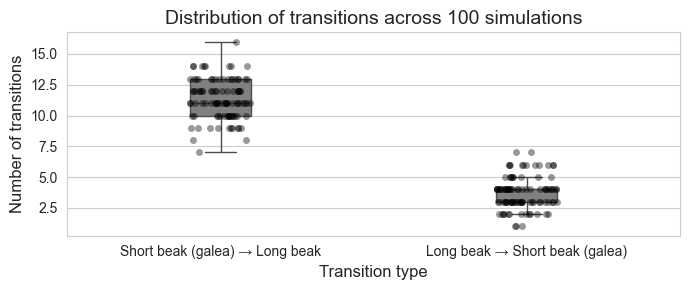

In [28]:
# set up
plt.figure(figsize=(7, 3))
sns.set_style("whitegrid")

# draw the xoxplot
sns.boxplot(
    data=beak_transition, 
    x='transition', 
    y='count', 
    color = "grey",
    showfliers=False,      # Hide outliers to avoid double-plotting dots 
    width=0.2
)

# overlay the dots
sns.stripplot(
    data=beak_transition, 
    x='transition', 
    y='count', 
    color='black', 
    size=5, 
    alpha=0.4,            
    jitter=True            # Spreads dots horizontally so they don't stack
)

# add labels
plt.title("Distribution of transitions across 100 simulations", fontsize=14)
plt.xlabel("Transition type", fontsize=12)
plt.ylabel("Number of transitions", fontsize=12)
# plt.xticks(rotation=45)

plt.tight_layout()
# plt.savefig("transition_plot.png")

In [29]:
# further examining statistics across replicates.
replicate_dwell = (
    tube_result["dwell"].pivot(index="map_id", columns="state", values="total_time")
    .round(3)
)
replicate_dwell.head(9)

state,0,1
map_id,,
0,6.864,2.945
1,7.855,1.954
2,6.989,2.820
3,7.277,2.531
4,7.504,2.305
5,7.182,2.626
6,7.430,2.378
7,7.139,2.670
8,6.347,3.461


In [30]:
# transition rate (0-short, 1-long)
tube_transition = tube_result["transitions"]

# create transition column
state_names = {0: "Short tube (<=3cm)", 1: "Long tube (>3 cm)"}
tube_transition['from_label'] = tube_transition['from_state_idx'].map(state_names)
tube_transition['to_label'] = tube_transition['to_state_idx'].map(state_names)

tube_transition['transition'] = tube_transition['from_label'] + " → " + tube_transition['to_label']

tube_transition.head(12)

,map_id,from_state_idx,to_state_idx,from_state,to_state,count,from_label,to_label,transition
0,0,0,1,0,1,19,Short tube (<=3cm),Long tube (>3 cm),Short tube (<=3cm) → Long tube (>3 cm)
1,0,1,0,1,0,10,Long tube (>3 cm),Short tube (<=3cm),Long tube (>3 cm) → Short tube (<=3cm)
2,1,0,1,0,1,21,Short tube (<=3cm),Long tube (>3 cm),Short tube (<=3cm) → Long tube (>3 cm)
3,1,1,0,1,0,11,Long tube (>3 cm),Short tube (<=3cm),Long tube (>3 cm) → Short tube (<=3cm)
4,2,0,1,0,1,23,Short tube (<=3cm),Long tube (>3 cm),Short tube (<=3cm) → Long tube (>3 cm)
5,2,1,0,1,0,10,Long tube (>3 cm),Short tube (<=3cm),Long tube (>3 cm) → Short tube (<=3cm)
6,3,0,1,0,1,23,Short tube (<=3cm),Long tube (>3 cm),Short tube (<=3cm) → Long tube (>3 cm)
7,3,1,0,1,0,14,Long tube (>3 cm),Short tube (<=3cm),Long tube (>3 cm) → Short tube (<=3cm)
8,4,0,1,0,1,21,Short tube (<=3cm),Long tube (>3 cm),Short tube (<=3cm) → Long tube (>3 cm)
9,4,1,0,1,0,13,Long tube (>3 cm),Short tube (<=3cm),Long tube (>3 cm) → Short tube (<=3cm)


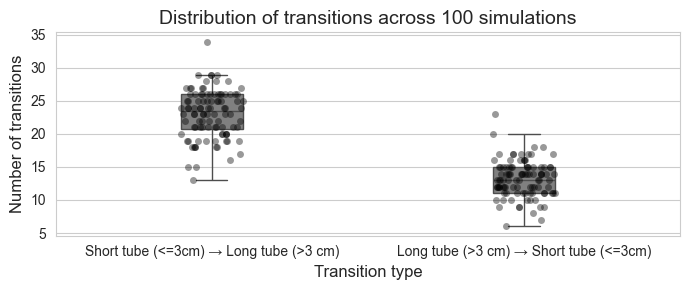

In [31]:
# set up
plt.figure(figsize=(7, 3))
sns.set_style("whitegrid")

# draw the xoxplot
sns.boxplot(
    data=tube_transition, 
    x='transition', 
    color = "grey",
    y='count', 
    showfliers=False,      # Hide outliers to avoid double-plotting dots 
    width=0.2
)

# overlay the dots
sns.stripplot(
    data=tube_transition, 
    x='transition', 
    y='count', 
    color='black', 
    size=5, 
    alpha=0.4,            
    jitter=True            # Spreads dots horizontally so they don't stack
)

# add labels
plt.title("Distribution of transitions across 100 simulations", fontsize=14)
plt.xlabel("Transition type", fontsize=12)
plt.ylabel("Number of transitions", fontsize=12)
# plt.xticks(rotation=20)

plt.tight_layout()
# plt.savefig("transition_plot.png")

# 5. Ancestral trait reconstruction

In [32]:
# fit a CTMC model and infer ancestral state posterior probabilities
color_asr = tree.pcm.infer_ancestral_states_discrete_ctmc(
data=tree.get_node_data("color").astype('Int64'),
nstates=3,
model="ARD",
)
# get matrix
color_posteriors = color_asr["data"]["trait_anc_posterior"]

In [33]:
# fit a CTMC model and infer ancestral state posterior probabilities
beak_asr = tree.pcm.infer_ancestral_states_discrete_ctmc(
data=tree.get_node_data("beak").astype('Int64'),
nstates=2,
model="ARD",
)
# get matrix
beak_posteriors = beak_asr["data"]["trait_anc_posterior"]

In [34]:
# fit a CTMC model and infer ancestral state posterior probabilities
tube_asr = tree.pcm.infer_ancestral_states_discrete_ctmc(
data=tree.get_node_data("tube").astype('Int64'),
nstates=2,
model="ARD",
)
# get matrix
tube_posteriors = tube_asr["data"]["trait_anc_posterior"]

# 6. Draw the tree

In [35]:
# visualize map
# draw tree
canvas, axes, mark = tree.draw(width=800)

# add color (white-0, pink-1, yellow-2)
fcolor_map = {'#D3D3D3':0, '#E5989B':1, '#E9C46A':2}

# add map
tree.annotate.add_edge_stochastic_map(
axes,
data=color_result["segments"],
map_id=2,
color=fcolor_map,
width=4,
);

# add ancestral trait reconstr
tree.annotate.add_node_pie_markers(
axes, data=color_posteriors,
colors=fcolor_map, size=[8 if node in tree.get_tip_data("idx") else 12 for node in tree.get_node_data("idx")],
istroke="black", istroke_width=1,
); 

<svg class="toyplot-canvas-Canvas" xmlns:toyplot="http://www.sandia.gov/toyplot" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns="http://www.w3.org/2000/svg" width="800.0px" height="1000.0px" viewBox="0 0 800.0 1000.0" preserveAspectRatio="xMidYMid meet" style="background-color:transparent;border-color:#292724;border-style:none;border-width:1.0;fill:rgb(16.1%,15.3%,14.1%);fill-opacity:1.0;font-family:Helvetica;font-size:12px;opacity:1.0;stroke:rgb(16.1%,15.3%,14.1%);stroke-opacity:1.0;stroke-width:1.0" id="tc03a51c4a6354379a5796fc280151c13"> Rehmannia-glutinosa-SRR11748982 Lindenbergia-muraria-SRR11934227 Melampyrum-roseum-DRR082665 Phtheirospermum-japonicum-DRR234970 Triphysaria-versicolor-SRR104381 Aureolaria-pectinata-SRR5150740 longicaulis-JJ131 rhodotricha-DE534 cinerascens-DE542 ingens-JJ15 ingens-DE216 lachnoglossa-DE536 mollis-JJ74 batangensis-DE566 dichotoma-JJ23 alaschanica-DE229 integrifolia-DE152 rhynchotricha-JJ99 metaszetschuanica-DE668 lutescens-DE126 urceolata-DE546 cephalantha-DE115 chumbica-JJ86 pseudomelampyriflora-DE563 pectinatiformis-DE666 brevilabris-DE127 densispica-DE554 anas-yellow-DE575 anas-purple-DE681 anas-yellow-DE765 semitorta-yellow-DE680 semitorta-magenta-DE623 kansuensis-white-DE528 kansuensis-yellow-DE162 kansuensis-pink-DE507 kansuensis-purple-DE704 kansuensis-white-DE704 keiskei-DRR082660 axillaris-JJ125 rhinanthoides-DE560 macrosiphon-DE519 macrosiphon-DE741 bella-JJ85 przewalskii-SRR3407095 przewalskii-DE69 fetisowii-DE523 streptorhyncha-SRR3407096 cyathophylloides-SRR3407086 cyathophylloides-DE181 superba-SRR3407088 cyathophylla-DE561 cyathophylla-SRR3424066 rex-subsp-thamnophila-SRR3407093 rex-subsp-rex-yellow-SRR3407092 rex-subsp-pseudothamnophila-SRR3407094 rex-subsp-rex-yellow-DE503 rex-subsp-rex-white-DE505 rex-subsp-lipskyana-red-DE510 rex-subsp-lipskyana-red-SRR3407087 delavayi-DE476 tenuituba-DE541 mussotii-DE550 longiflora-red-DE531 longiflora-red-JJ36 longiflora-nored-DE696 longiflora-red-DE696 chinensis-DE737 bidentata-DE672 decorissima-DE164 armata-DE671 armata-DE643 souliei-DE549 oxycarpa-DE504 torta-aff-purple-DE764 torta-yellow-purple-DE736 davidii-DE509 fletcheri-JJ89 latituba-DE88 tricolor-JJ130 cranolopha-purple-JJ109 cranolopha-forked-DE189 cranolopha-unforked-DE173 cranolopha-forked-DE151 <path id="Line-789" d="M 452.17357 726.8 L 452.17357 718.7" style="fill:rg

In [105]:
toyplot.svg.render(canvas, f"color.svg")

In [36]:
# visualize map
# draw tree
canvas, axes, mark = tree.draw(width = 800)

# add color (white-0-short, black-1-long)
fbeak_map = {'#D3D3D3':0, '#000000':1}

# add map
tree.annotate.add_edge_stochastic_map(
axes,
data=beak_result["segments"],
map_id=1,
color=fbeak_map,
width=4,
);

# add ancestral trait reconstr
tree.annotate.add_node_pie_markers(
axes, data=beak_posteriors,
colors=fbeak_map, size=[8 if node in tree.get_tip_data("idx") else 12 for node in tree.get_node_data("idx")],
#istroke="black", istroke_width=1,
); 

<svg class="toyplot-canvas-Canvas" xmlns:toyplot="http://www.sandia.gov/toyplot" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns="http://www.w3.org/2000/svg" width="800.0px" height="1000.0px" viewBox="0 0 800.0 1000.0" preserveAspectRatio="xMidYMid meet" style="background-color:transparent;border-color:#292724;border-style:none;border-width:1.0;fill:rgb(16.1%,15.3%,14.1%);fill-opacity:1.0;font-family:Helvetica;font-size:12px;opacity:1.0;stroke:rgb(16.1%,15.3%,14.1%);stroke-opacity:1.0;stroke-width:1.0" id="t88aed625c0364896947987366232ef99"> Rehmannia-glutinosa-SRR11748982 Lindenbergia-muraria-SRR11934227 Melampyrum-roseum-DRR082665 Phtheirospermum-japonicum-DRR234970 Triphysaria-versicolor-SRR104381 Aureolaria-pectinata-SRR5150740 longicaulis-JJ131 rhodotricha-DE534 cinerascens-DE542 ingens-JJ15 ingens-DE216 lachnoglossa-DE536 mollis-JJ74 batangensis-DE566 dichotoma-JJ23 alaschanica-DE229 integrifolia-DE152 rhynchotricha-JJ99 metaszetschuanica-DE668 lutescens-DE126 urceolata-DE546 cephalantha-DE115 chumbica-JJ86 pseudomelampyriflora-DE563 pectinatiformis-DE666 brevilabris-DE127 densispica-DE554 anas-yellow-DE575 anas-purple-DE681 anas-yellow-DE765 semitorta-yellow-DE680 semitorta-magenta-DE623 kansuensis-white-DE528 kansuensis-yellow-DE162 kansuensis-pink-DE507 kansuensis-purple-DE704 kansuensis-white-DE704 keiskei-DRR082660 axillaris-JJ125 rhinanthoides-DE560 macrosiphon-DE519 macrosiphon-DE741 bella-JJ85 przewalskii-SRR3407095 przewalskii-DE69 fetisowii-DE523 streptorhyncha-SRR3407096 cyathophylloides-SRR3407086 cyathophylloides-DE181 superba-SRR3407088 cyathophylla-DE561 cyathophylla-SRR3424066 rex-subsp-thamnophila-SRR3407093 rex-subsp-rex-yellow-SRR3407092 rex-subsp-pseudothamnophila-SRR3407094 rex-subsp-rex-yellow-DE503 rex-subsp-rex-white-DE505 rex-subsp-lipskyana-red-DE510 rex-subsp-lipskyana-red-SRR3407087 delavayi-DE476 tenuituba-DE541 mussotii-DE550 longiflora-red-DE531 longiflora-red-JJ36 longiflora-nored-DE696 longiflora-red-DE696 chinensis-DE737 bidentata-DE672 decorissima-DE164 armata-DE671 armata-DE643 souliei-DE549 oxycarpa-DE504 torta-aff-purple-DE764 torta-yellow-purple-DE736 davidii-DE509 fletcheri-JJ89 latituba-DE88 tricolor-JJ130 cranolopha-purple-JJ109 cranolopha-forked-DE189 cranolopha-unforked-DE173 cranolopha-forked-DE151 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 0, 1 1, 0 1, 0 0, 1 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 1, 0 1, 0 0, 1 0, 1 0, 1 1, 0 0, 1 1, 0 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 1, 0 1, 0 0, 1 0, 1 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0.873352, 0.126648 0.835769, 0.164231 0.00543623, 0.994564 0.968159, 0.0318408 0.0256955, 0.974305 0.00026638, 0.999734 0.000280016, 0.99972 2.90655e-05, 0.999971 0.000219592, 0.99978 0.000689725, 0.99931 0.00152565, 0.998474 0.985441, 0.0145591 0.141974, 0.858026 0.108201, 0.891799 0.00129147, 0.998709 2.37186e-06, 0.999998 1.28705e-05, 0.999987 0.000118703, 0.999881 0.99994, 6.01289e-05 1, 3.35797e-07 0.9995, 0.000499692 0.997961, 0.00203939 0.00637179, 0.993628 0.000978222, 0.999022 0.000513548, 0.999486 0.00164067, 0.998359 3.46721e-05, 0.999965 7.33489e-05, 0.999927 0.000232767, 0.999767 0.000184856, 0.999815 0.000250438, 0.99975 4.92446e-06, 0.999995 0.000164507, 0.999835 0.985394, 0.0146062 2.91389e-05, 0.999971 0.0127347, 0.987265 0.384138, 0.615862 1, 5.53239e-08 0.999998, 1.54718e-06 0.999995, 4.92066e-06 0.999942, 5.84487e-05 0.999716, 0.00028392 0.986546, 0.0134543 0.402553, 0.597447 0.00113931, 0.998861 0.000688075, 0.999312 4.75139e-05, 0.999952 8.27194e-05, 0.999917 8.03656e-08, 1 6.11768e-07, 0.999999 8.68144e-06, 0.999991 4.86699e-05, 0.999951 1.18086e-05, 0.999988 6.91218e-06, 0.999993 3.77317e-06, 0.999996 1.21991e-05, 0.999988 3.2027e-05, 0.999968 1.73814e-05, 0.999983 1.44834e-05, 0.999986 2.12146e-06, 0.999998 1.19753e-06, 0.999999 6.79456e-07, 0.999999

In [107]:
toyplot.svg.render(canvas, f"beak.svg")

In [37]:
# visualize map
# draw tree
canvas, axes, mark = tree.draw(width = 800)

# add color (white-0-short, black-1-long)
ftube_map = {'#D3D3D3':0, '#000000':1}

# add map
tree.annotate.add_edge_stochastic_map(
axes,
data=tube_result["segments"],
map_id=1,
color=ftube_map,
width=4,
);

# add ancestral trait reconstr
tree.annotate.add_node_pie_markers(
axes, data=tube_posteriors,
colors=ftube_map, size=[8 if node in tree.get_tip_data("idx") else 12 for node in tree.get_node_data("idx")],
# istroke="black", istroke_width=1,
); 

<svg class="toyplot-canvas-Canvas" xmlns:toyplot="http://www.sandia.gov/toyplot" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns="http://www.w3.org/2000/svg" width="800.0px" height="1000.0px" viewBox="0 0 800.0 1000.0" preserveAspectRatio="xMidYMid meet" style="background-color:transparent;border-color:#292724;border-style:none;border-width:1.0;fill:rgb(16.1%,15.3%,14.1%);fill-opacity:1.0;font-family:Helvetica;font-size:12px;opacity:1.0;stroke:rgb(16.1%,15.3%,14.1%);stroke-opacity:1.0;stroke-width:1.0" id="t445ef3d20ca643c78729d7288dfb7629"> Rehmannia-glutinosa-SRR11748982 Lindenbergia-muraria-SRR11934227 Melampyrum-roseum-DRR082665 Phtheirospermum-japonicum-DRR234970 Triphysaria-versicolor-SRR104381 Aureolaria-pectinata-SRR5150740 longicaulis-JJ131 rhodotricha-DE534 cinerascens-DE542 ingens-JJ15 ingens-DE216 lachnoglossa-DE536 mollis-JJ74 batangensis-DE566 dichotoma-JJ23 alaschanica-DE229 integrifolia-DE152 rhynchotricha-JJ99 metaszetschuanica-DE668 lutescens-DE126 urceolata-DE546 cephalantha-DE115 chumbica-JJ86 pseudomelampyriflora-DE563 pectinatiformis-DE666 brevilabris-DE127 densispica-DE554 anas-yellow-DE575 anas-purple-DE681 anas-yellow-DE765 semitorta-yellow-DE680 semitorta-magenta-DE623 kansuensis-white-DE528 kansuensis-yellow-DE162 kansuensis-pink-DE507 kansuensis-purple-DE704 kansuensis-white-DE704 keiskei-DRR082660 axillaris-JJ125 rhinanthoides-DE560 macrosiphon-DE519 macrosiphon-DE741 bella-JJ85 przewalskii-SRR3407095 przewalskii-DE69 fetisowii-DE523 streptorhyncha-SRR3407096 cyathophylloides-SRR3407086 cyathophylloides-DE181 superba-SRR3407088 cyathophylla-DE561 cyathophylla-SRR3424066 rex-subsp-thamnophila-SRR3407093 rex-subsp-rex-yellow-SRR3407092 rex-subsp-pseudothamnophila-SRR3407094 rex-subsp-rex-yellow-DE503 rex-subsp-rex-white-DE505 rex-subsp-lipskyana-red-DE510 rex-subsp-lipskyana-red-SRR3407087 delavayi-DE476 tenuituba-DE541 mussotii-DE550 longiflora-red-DE531 longiflora-red-JJ36 longiflora-nored-DE696 longiflora-red-DE696 chinensis-DE737 bidentata-DE672 decorissima-DE164 armata-DE671 armata-DE643 souliei-DE549 oxycarpa-DE504 torta-aff-purple-DE764 torta-yellow-purple-DE736 davidii-DE509 fletcheri-JJ89 latituba-DE88 tricolor-JJ130 cranolopha-purple-JJ109 cranolopha-forked-DE189 cranolopha-unforked-DE173 cranolopha-forked-DE151 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 1, 0 0, 1 0, 1 1, 0 1, 0 0, 1 0, 1 1, 0 0, 1 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 1, 0 1, 0 1, 0 1, 0 1, 0 1, 0 0, 1 0, 1 0, 1 0, 1 0, 1 0, 1 0.863262, 0.136738 0.853622, 0.146378 0.990812, 0.00918755 0.997626, 0.00237378 0.987599, 0.0124014 0.940322, 0.0596783 0.943019, 0.0569813 0.915482, 0.084518 0.648597, 0.351403 0.725013, 0.274987 0.778625, 0.221375 0.998408, 0.00159176 0.982392, 0.0176076 0.933926, 0.0660736 0.885931, 0.114069 0.999473, 0.000526509 0.998599, 0.00140143 0.994516, 0.00548435 0.999731, 0.000268554 0.999995, 5.48479e-06 0.999381, 0.000619494 0.999054, 0.00094592 0.951411, 0.0485886 0.940248, 0.0597516 0.894033, 0.105967 0.873183, 0.126817 0.820152, 0.179848 0.698314, 0.301686 0.685384, 0.314616 0.033051, 0.966949 0.221178, 0.778822 0.000243323, 0.999757 0.835099, 0.164901 0.000823145, 0.999177 0.000229352, 0.999771 0.046686, 0.953314 0.0411591, 0.958841 0.999999, 1.48879e-06 0.999945, 5.53692e-05 0.999633, 0.000367149 0.997203, 0.00279674 0.994196, 0.00580436 0.941575, 0.058425 0.215712, 0.784288 0.182129, 0.817871 0.173308, 0.826692 0.180559, 0.819441 0.0020149, 0.997985 1.16199e-06, 0.999999 1.09523e-05, 0.999989 0.000228624, 0.999771 0.0179623, 0.982038 0.0001929, 0.999807 0.00012859, 0.999871 8.18298e-05, 0.999918 0.000272199, 0.999728 0.788829, 0.211171 0.976522, 0.0234777 0.929593, 0.0704066 0.687479, 0.312521 1.86768e-05, 0.999981 1.11478e-05, 0.999989 4.27545e-05, 0.999957 0.000227332, 

In [109]:
toyplot.svg.render(canvas, f"tube.svg")